Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.9/35.9 MB 58.9 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 93.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [rasterio]4/5 [rasterio]



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
/home/jovyan/.local/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(



SENTINEL-1 LULC MONTHLY PROTOTYPE



Enter latitude:  39.3300
Enter longitude:  554946


Invalid coordinates: Longitude must be between -180 and 180.



Enter latitude:  95
Enter longitude:  39.3300


Invalid coordinates: Latitude must be between -90 and 90.



Enter latitude:  39.3300
Enter longitude:  -0.3400
Enter start month (YYYY-MM, e.g. 2025-01):  2024-01



CONFIRM YOUR INPUTS
Latitude: 39.33
Longitude: -0.34
Output start: 2024-01
Output end: 2024-12
Data start: 2023-02
Data end: 2024-12
Monthly composites required: 23
Monthly maps generated: 12
Model: E23 ResNet34 U-Net
Training: Disabled



Proceed with data retrieval? Type yes to continue:  yes



Inputs confirmed. Starting prototype.

Device: cuda
GPU: NVIDIA RTX A6000

Initializing Earth Engine...
Earth Engine initialized.

Grid:
CRS: EPSG:32630
Dimensions: 256 x 256
Pixel size: 30 m
Grid width: 7.68 km

Loading E23 checkpoint...
Checkpoint loaded successfully.
Epoch: 8
Validation mIoU: 0.5001583099365234

DOWNLOADING 23 SENTINEL-1 MONTHLY COMPOSITES

[1/23] Downloading 2023-02...
  Scenes: 15
  Requested month: 2023-02
  Actual source month: 2023-02
  Fallback used: False
  SAR shape: (2, 256, 256)
  Validity: 100.00%

[2/23] Downloading 2023-03...
  Scenes: 15
  Requested month: 2023-03
  Actual source month: 2023-03
  Fallback used: False
  SAR shape: (2, 256, 256)
  Validity: 100.00%

[3/23] Downloading 2023-04...
  Scenes: 15
  Requested month: 2023-04
  Actual source month: 2023-04
  Fallback used: False
  SAR shape: (2, 256, 256)
  Validity: 100.00%

[4/23] Downloading 2023-05...
  Scenes: 15
  Requested month: 2023-05
  Actual source month: 2023-05
  Fallback used: Fa

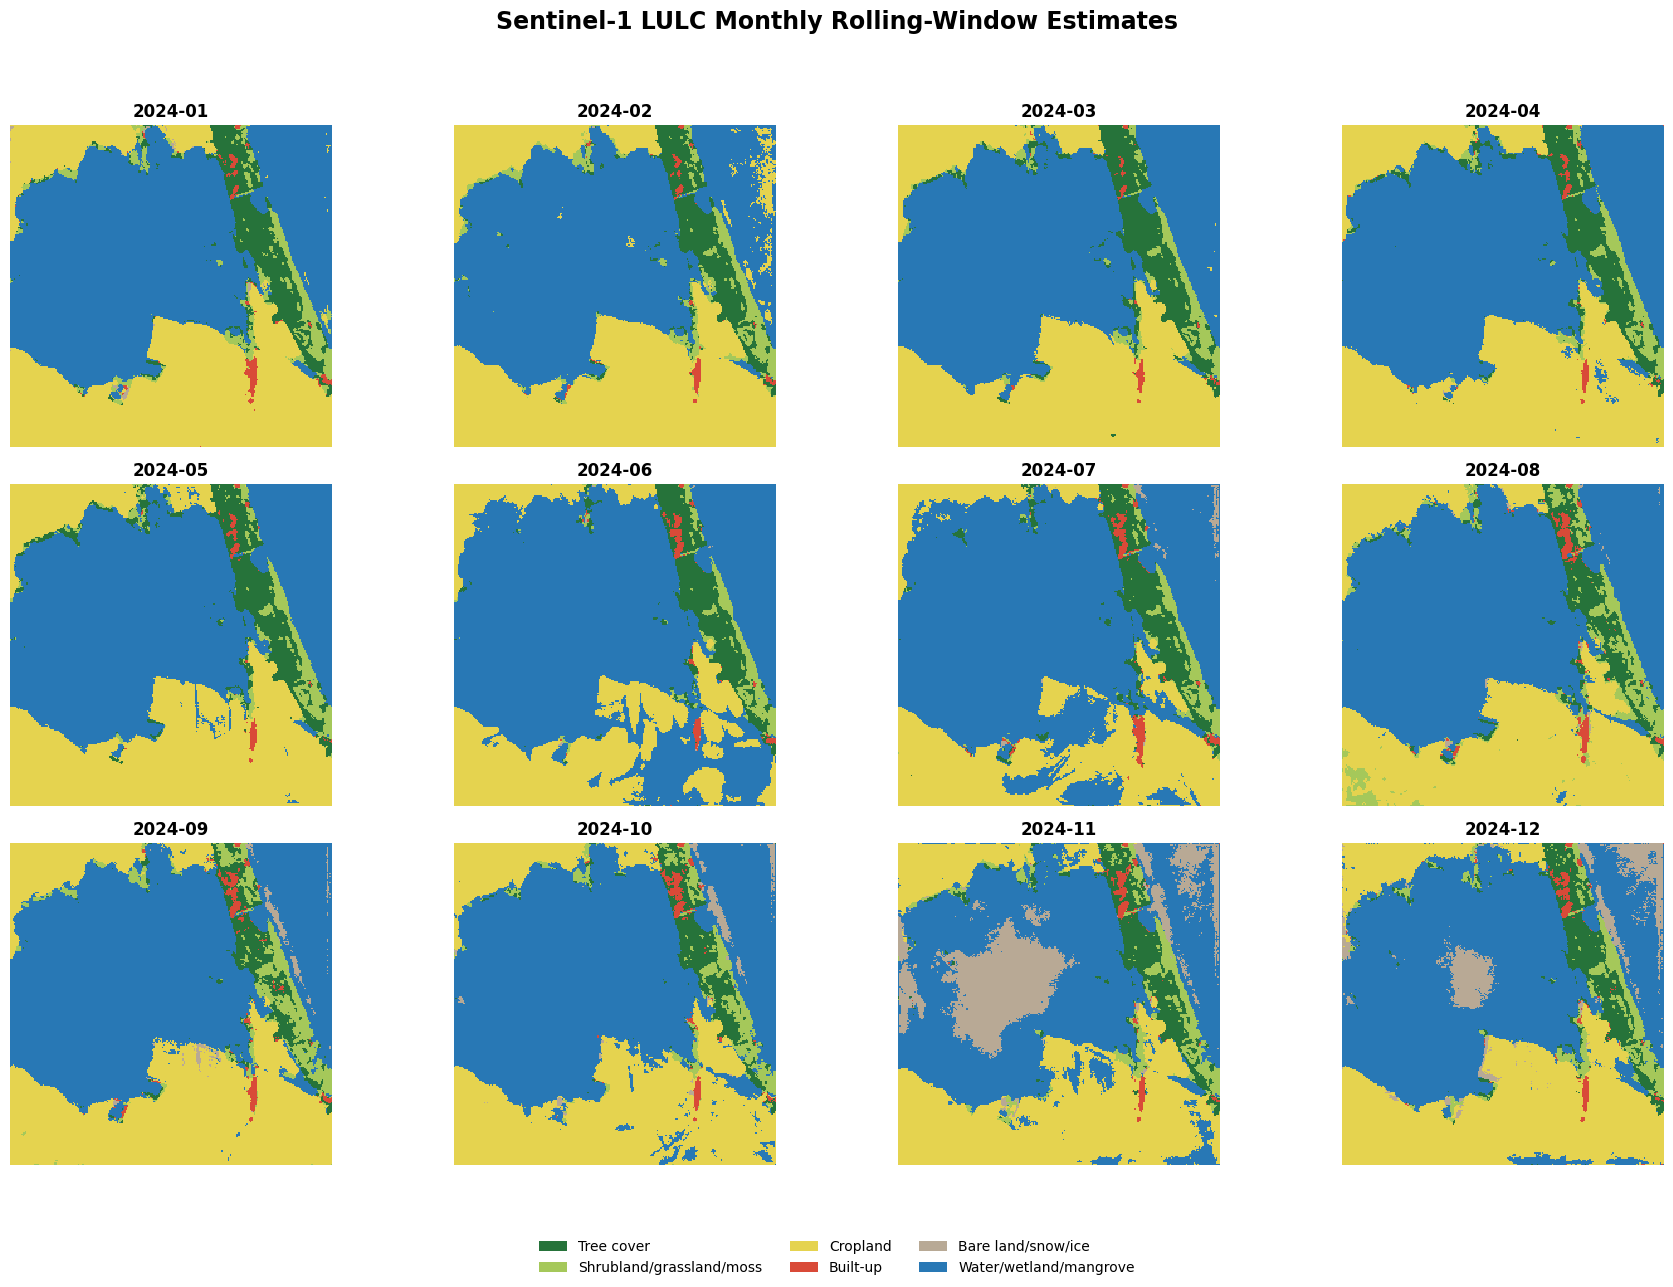

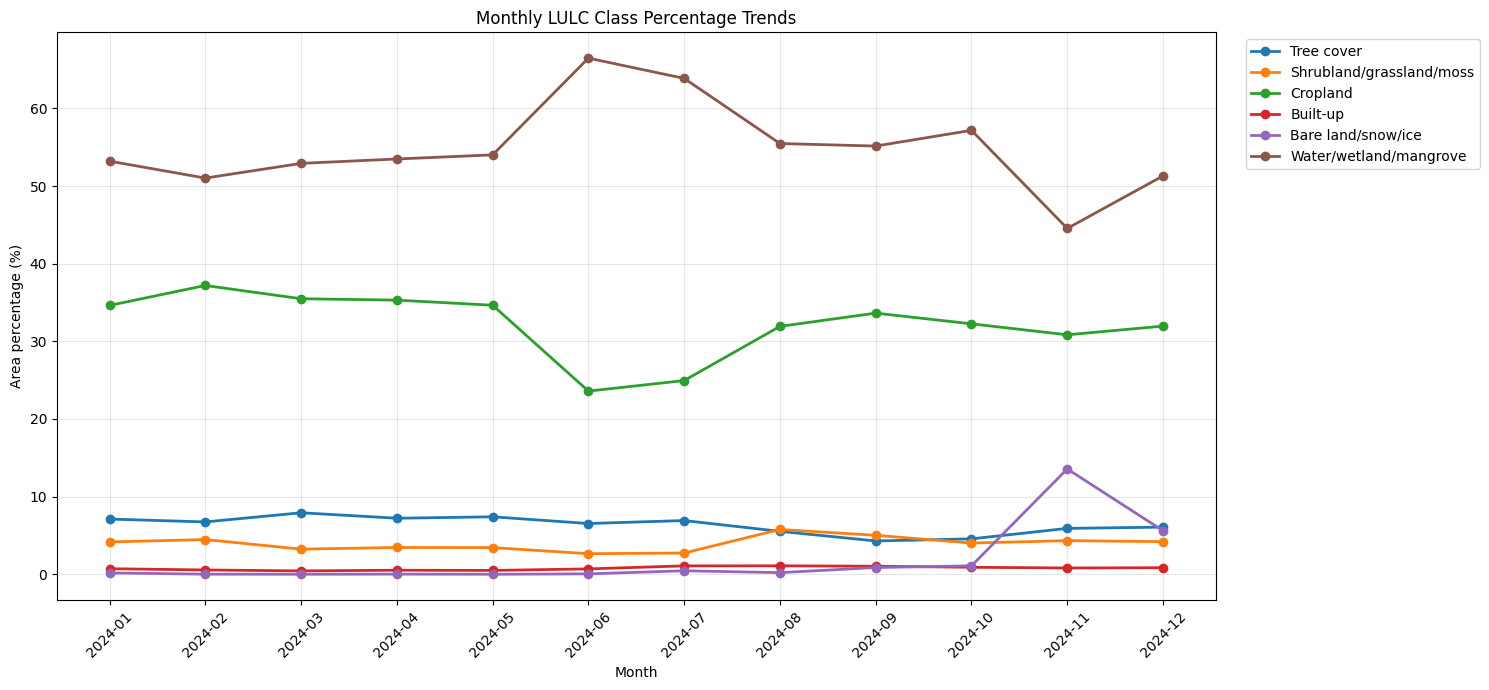

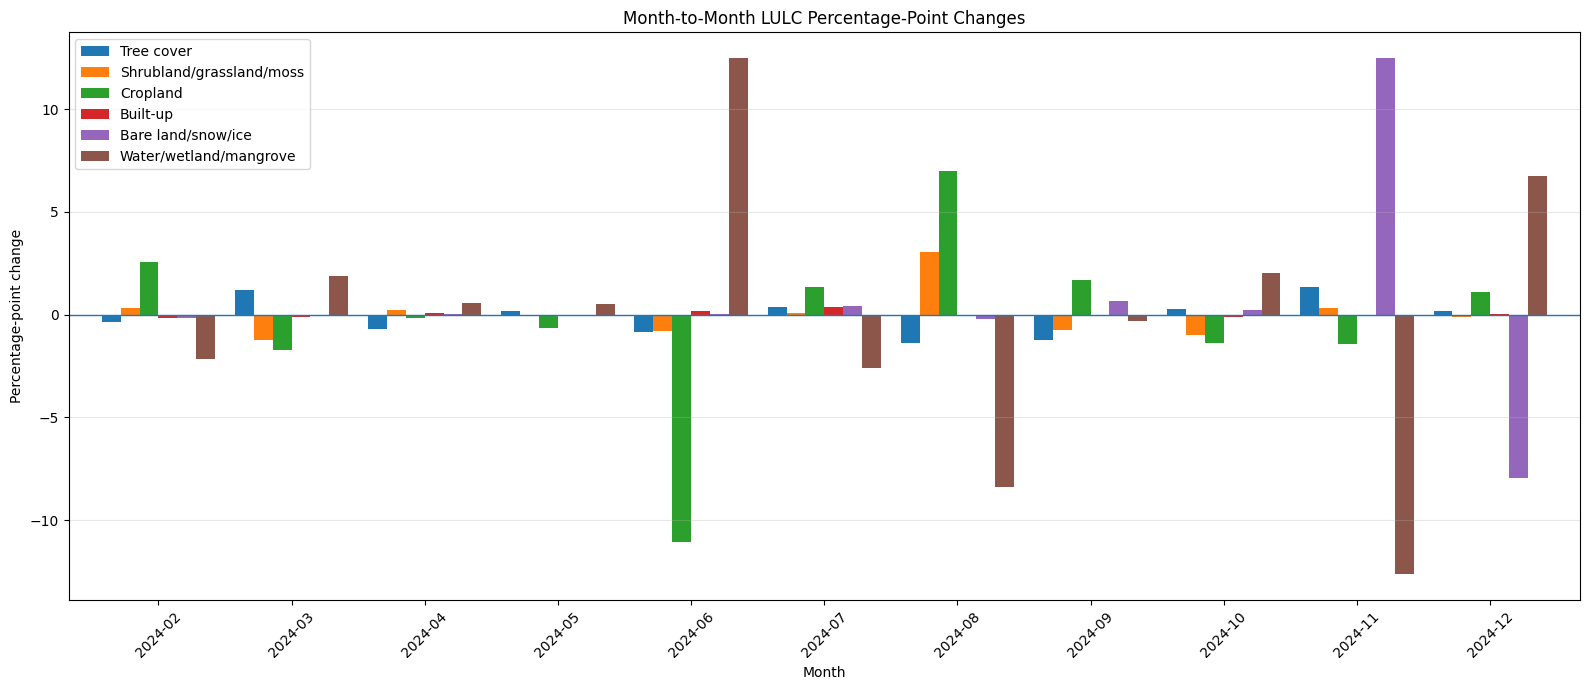

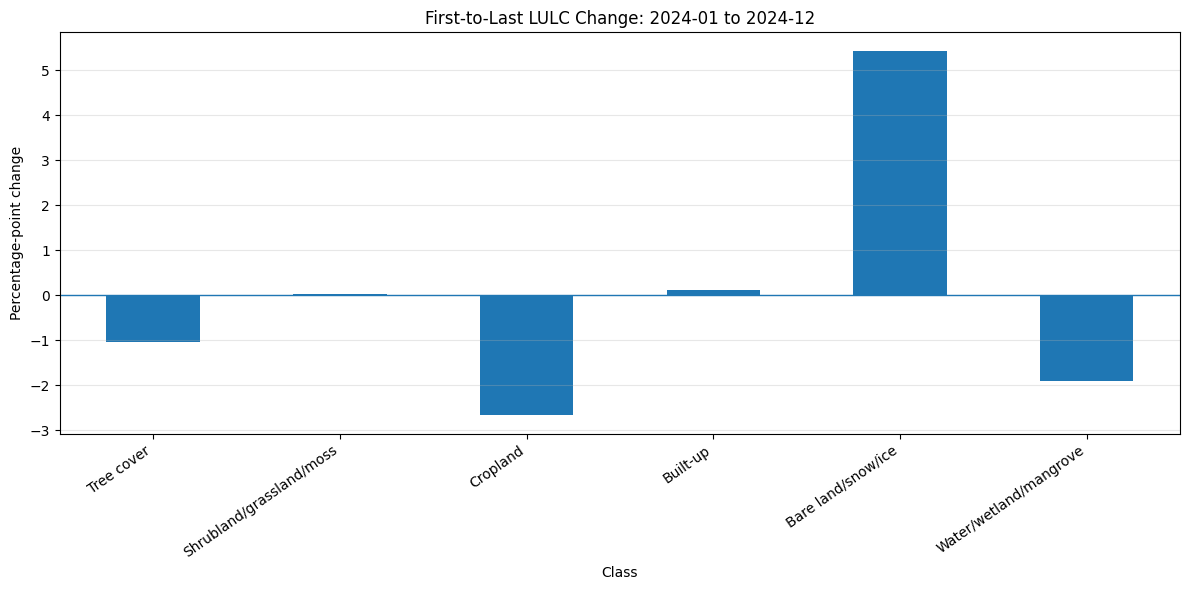


PROTOTYPE COMPLETED
Location: 39.33 -0.34
Output period: 2024-01 to 2024-12

First-to-last percentage-point changes:
Tree cover                 -1.04
Shrubland/grassland/moss    0.04
Cropland                   -2.67
Built-up                    0.13
Bare land/snow/ice          5.44
Water/wetland/mangrove     -1.90

Fallback months: 0

Output directory:
/home/jovyan/vault/LULC_Project/results/E23_monthly_prototype

Generated files:
12_month_lulc_maps.png                        0.26 MB
all_12_lulc_maps.png                          1.42 MB
class_percentages_over_time.png               0.20 MB
first_to_last_change.png                      0.15 MB
first_to_last_change_pp.csv                   0.00 MB
map_01.png                                    0.07 MB
map_02.png                                    0.07 MB
map_03.png                                    0.07 MB
map_04.png                                    0.07 MB
map_05.png                                    0.07 MB
map_06.png               

In [1]:
# =============================================================================
# SENTINEL-1 LULC MONTHLY PROTOTYPE — E23
# COMPLETE PIPELINE | NO RETRAINING
#
# Inputs: latitude, longitude, start month
# Outputs: 12 maps, class percentages, area, changes, charts and CSV files
#
# FIXES:
# 1. Exact 256 x 256 download dimensions
# 2. Missing Sentinel-1 months handled using nearby-month fallback
# 3. Actual source month recorded for every composite
# 4. E23 checkpoint reused; no training
# =============================================================================


# =============================================================================
# 1. INSTALL DEPENDENCIES
# =============================================================================

import sys
import subprocess
import importlib.util

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "requests": "requests",
    "rasterio": "rasterio",
    "pyproj": "pyproj",
    "ee": "earthengine-api",
    "torch": "torch"
}

missing = [
    package
    for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        *missing
    ])


# =============================================================================
# 2. IMPORT LIBRARIES
# =============================================================================

import os
import io
import json
import time
import zipfile
import warnings

from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import rasterio
import ee
import torch
import torch.nn as nn
import torch.nn.functional as F

from rasterio.io import MemoryFile
from pyproj import Transformer
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")


# =============================================================================
# 3. USER INPUT — BEFORE ANY DOWNLOAD
# =============================================================================

print("\n" + "=" * 75)
print("SENTINEL-1 LULC MONTHLY PROTOTYPE")
print("=" * 75)

while True:
    try:
        LATITUDE = float(input("\nEnter latitude: ").strip())
        LONGITUDE = float(input("Enter longitude: ").strip())

        if not -90 <= LATITUDE <= 90:
            raise ValueError("Latitude must be between -90 and 90.")

        if not -180 <= LONGITUDE <= 180:
            raise ValueError("Longitude must be between -180 and 180.")

        break

    except ValueError as e:
        print("Invalid coordinates:", e)


while True:
    START_MONTH_INPUT = input(
        "Enter start month (YYYY-MM, e.g. 2025-01): "
    ).strip()

    try:
        START_PERIOD = pd.Period(
            START_MONTH_INPUT,
            freq="M"
        )
        break

    except Exception:
        print("Invalid month. Use YYYY-MM.")


OUTPUT_END_PERIOD = START_PERIOD + 11

CURRENT_PERIOD = pd.Period(
    datetime.now().strftime("%Y-%m"),
    freq="M"
)

LAST_COMPLETED_PERIOD = CURRENT_PERIOD - 1

if OUTPUT_END_PERIOD > LAST_COMPLETED_PERIOD:
    raise ValueError(
        f"Your requested end month is {OUTPUT_END_PERIOD}, "
        f"but the latest completed month is {LAST_COMPLETED_PERIOD}."
    )

# 12 rolling 12-month windows require 23 monthly observations.
DATA_START_PERIOD = START_PERIOD - 11
DATA_END_PERIOD = OUTPUT_END_PERIOD

print("\n" + "=" * 75)
print("CONFIRM YOUR INPUTS")
print("=" * 75)

print("Latitude:", LATITUDE)
print("Longitude:", LONGITUDE)
print("Output start:", START_PERIOD)
print("Output end:", OUTPUT_END_PERIOD)
print("Data start:", DATA_START_PERIOD)
print("Data end:", DATA_END_PERIOD)
print("Monthly composites required: 23")
print("Monthly maps generated: 12")
print("Model: E23 ResNet34 U-Net")
print("Training: Disabled")

confirm = input(
    "\nProceed with data retrieval? Type yes to continue: "
).strip().lower()

if confirm != "yes":
    raise RuntimeError(
        "Cancelled. No Earth Engine download was started."
    )

print("\nInputs confirmed. Starting prototype.")


# =============================================================================
# 4. CONFIGURATION
# =============================================================================

PROJECT_ROOT = Path(
    "/home/jovyan/vault/LULC_Project"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "results"
    / "exp23_e21_targeted_finetune"
    / "checkpoints"
    / "best_exp23.pth"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "E23_monthly_prototype"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EE_PROJECT = "final-project-513714"

IMAGE_SIZE = 256
PIXEL_SIZE = 30

INPUT_MONTHS = 12
OUTPUT_MONTHS = 12
NUM_CLASSES = 6

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = [
    "Tree cover",
    "Shrubland/grassland/moss",
    "Cropland",
    "Built-up",
    "Bare land/snow/ice",
    "Water/wetland/mangrove"
]

CLASS_COLORS = [
    "#26733A",
    "#A5C85A",
    "#E5D34F",
    "#D94A38",
    "#B8A995",
    "#2878B5"
]

VV_MEDIAN = -10.296875
VV_IQR = 5.75

VH_MEDIAN = -16.9375
VH_IQR = 6.765625

VV_FILL = VV_MEDIAN
VH_FILL = VH_MEDIAN

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"E23 checkpoint not found: {CHECKPOINT_PATH}"
    )

print("\nDevice:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# =============================================================================
# 5. EARTH ENGINE INITIALIZATION
# =============================================================================

print("\nInitializing Earth Engine...")

try:
    ee.Initialize(project=EE_PROJECT)

except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)

print("Earth Engine initialized.")


# =============================================================================
# 6. DEFINE AN EXACT 256 x 256 UTM GRID
# =============================================================================

utm_zone = int((LONGITUDE + 180) // 6) + 1
utm_zone = max(1, min(60, utm_zone))

if LATITUDE >= 0:
    CRS = f"EPSG:{32600 + utm_zone}"
else:
    CRS = f"EPSG:{32700 + utm_zone}"

transformer = Transformer.from_crs(
    "EPSG:4326",
    CRS,
    always_xy=True
)

center_x, center_y = transformer.transform(
    LONGITUDE,
    LATITUDE
)

GRID_WIDTH = IMAGE_SIZE * PIXEL_SIZE

XMIN = center_x - GRID_WIDTH / 2
XMAX = center_x + GRID_WIDTH / 2
YMIN = center_y - GRID_WIDTH / 2
YMAX = center_y + GRID_WIDTH / 2

REGION = ee.Geometry.Rectangle(
    [XMIN, YMIN, XMAX, YMAX],
    proj=CRS,
    geodesic=False
)

print("\nGrid:")
print("CRS:", CRS)
print("Dimensions:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Pixel size:", PIXEL_SIZE, "m")
print("Grid width:", GRID_WIDTH / 1000, "km")


# =============================================================================
# 7. MODEL ARCHITECTURE
# =============================================================================

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class BasicBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out, inplace=True)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        return F.relu(out, inplace=True)


class UpBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):
        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat(
            [x, skip],
            dim=1
        )

        return self.conv(x)


class ResNet34UNet(nn.Module):

    def __init__(
        self,
        in_channels=48,
        num_classes=6
    ):
        super().__init__()

        self.input_projection = ConvBlock(
            in_channels,
            32
        )

        self.conv1 = nn.Conv2d(
            in_channels,
            64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(64)

        self.maxpool = nn.MaxPool2d(
            3,
            stride=2,
            padding=1
        )

        self.in_channels = 64

        self.layer1 = self._make_layer(
            64, 3, 1
        )

        self.layer2 = self._make_layer(
            128, 4, 2
        )

        self.layer3 = self._make_layer(
            256, 6, 2
        )

        self.layer4 = self._make_layer(
            512, 3, 2
        )

        self.decoder4 = UpBlock(512, 256, 256)
        self.decoder3 = UpBlock(256, 128, 128)
        self.decoder2 = UpBlock(128, 64, 64)
        self.decoder1 = UpBlock(64, 64, 64)
        self.decoder0 = UpBlock(64, 32, 32)

        self.classifier = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def _make_layer(
        self,
        out_channels,
        blocks,
        stride
    ):

        layers = [
            BasicBlock(
                self.in_channels,
                out_channels,
                stride
            )
        ]

        self.in_channels = out_channels

        for _ in range(1, blocks):

            layers.append(
                BasicBlock(
                    self.in_channels,
                    out_channels,
                    1
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):

        input_skip = self.input_projection(x)

        stem = self.conv1(x)
        stem = self.bn1(stem)
        stem = F.relu(stem, inplace=True)

        x = self.maxpool(stem)

        layer1 = self.layer1(x)
        layer2 = self.layer2(layer1)
        layer3 = self.layer3(layer2)
        layer4 = self.layer4(layer3)

        x = self.decoder4(layer4, layer3)
        x = self.decoder3(x, layer2)
        x = self.decoder2(x, layer1)
        x = self.decoder1(x, stem)
        x = self.decoder0(x, input_skip)

        return self.classifier(x)


# =============================================================================
# 8. LOAD E23 CHECKPOINT
# =============================================================================

print("\nLoading E23 checkpoint...")

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu"
    )

if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]

elif "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]

else:
    state_dict = checkpoint

clean_state_dict = {}

for key, value in state_dict.items():

    if key.startswith("module."):
        key = key.replace("module.", "", 1)

    clean_state_dict[key] = value

model = ResNet34UNet(
    in_channels=48,
    num_classes=NUM_CLASSES
)

model.load_state_dict(
    clean_state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("Checkpoint loaded successfully.")

if isinstance(checkpoint, dict):
    print("Epoch:", checkpoint.get("epoch", "Unknown"))
    print("Validation mIoU:", checkpoint.get("val_miou", "Unknown"))


# =============================================================================
# 9. SENTINEL-1 COLLECTION AND MONTHLY COMPOSITE
# =============================================================================

def get_sentinel_collection(start_date, end_date):

    return (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(REGION)
        .filterDate(start_date, end_date)
        .filter(
            ee.Filter.eq("instrumentMode", "IW")
        )
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation",
                "VV"
            )
        )
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation",
                "VH"
            )
        )
        .select(["VV", "VH"])
    )


def create_monthly_composite(year, month):

    requested_period = pd.Period(
        f"{year}-{month:02d}",
        freq="M"
    )

    start_date = requested_period.start_time.strftime("%Y-%m-%d")
    end_date = (
        (requested_period + 1).start_time.strftime("%Y-%m-%d")
    )

    collection = get_sentinel_collection(
        start_date,
        end_date
    )

    scene_count = collection.size().getInfo()

    source_period = requested_period
    fallback_used = False

    if scene_count == 0:

        print(
            f"  WARNING: No Sentinel-1 scenes for {requested_period}."
        )

        # Search nearest months first.
        offsets = [-1, 1, -2, 2]

        for offset in offsets:

            candidate_period = requested_period + offset

            candidate_start = (
                candidate_period.start_time.strftime("%Y-%m-%d")
            )

            candidate_end = (
                (candidate_period + 1)
                .start_time.strftime("%Y-%m-%d")
            )

            candidate_collection = get_sentinel_collection(
                candidate_start,
                candidate_end
            )

            candidate_count = (
                candidate_collection.size().getInfo()
            )

            if candidate_count > 0:

                collection = candidate_collection
                scene_count = candidate_count
                source_period = candidate_period
                fallback_used = True

                print(
                    f"  FALLBACK: Using {source_period} "
                    f"({scene_count} scenes) for {requested_period}."
                )

                break

    if scene_count == 0:

        raise RuntimeError(
            f"No Sentinel-1 scenes found for {requested_period} "
            "or any of the four nearby months. "
            "Choose another location or date."
        )

    composite = collection.median()

    validity = (
        composite
        .mask()
        .rename(["valid_vv", "valid_vh"])
        .unmask(0)
    )

    fill_image = ee.Image.constant(
        [VV_FILL, VH_FILL]
    ).rename(["VV", "VH"])

    filled = composite.unmask(fill_image)

    output = (
        filled
        .select(["VV", "VH"])
        .addBands(validity)
        .toFloat()
    )

    metadata = {
        "requested_month": str(requested_period),
        "source_month": str(source_period),
        "scene_count": int(scene_count),
        "fallback_used": bool(fallback_used)
    }

    return output, metadata


# =============================================================================
# 10. READ DOWNLOADED GEOTIFF
# =============================================================================

def read_geotiff_response(content):

    memory = io.BytesIO(content)

    if zipfile.is_zipfile(memory):

        memory.seek(0)

        with zipfile.ZipFile(memory) as archive:

            tif_files = [
                name
                for name in archive.namelist()
                if name.lower().endswith((".tif", ".tiff"))
            ]

            if not tif_files:

                raise RuntimeError(
                    "No GeoTIFF found in downloaded archive."
                )

            content = archive.read(tif_files[0])

    with MemoryFile(content) as memfile:

        with memfile.open() as src:

            array = src.read()

    return array.astype(np.float32)


# =============================================================================
# 11. DOWNLOAD MONTH — EXACT DIMENSIONS
# =============================================================================

def download_month(year, month):

    image, metadata = create_monthly_composite(
        year,
        month
    )

    params = {
        "name": f"S1_{year}_{month:02d}",
        "crs": CRS,
        "dimensions": f"{IMAGE_SIZE}x{IMAGE_SIZE}",
        "region": REGION,
        "format": "GEO_TIFF",
        "filePerBand": False
    }

    last_error = None

    for attempt in range(1, 4):

        try:

            url = image.getDownloadURL(params)

            response = requests.get(
                url,
                timeout=180
            )

            response.raise_for_status()

            array = read_geotiff_response(
                response.content
            )

            if array.ndim != 3:

                raise RuntimeError(
                    f"Unexpected raster dimensions: {array.shape}"
                )

            if array.shape[0] != 4:

                raise RuntimeError(
                    f"Expected 4 bands, received {array.shape}"
                )

            if array.shape[1:] != (
                IMAGE_SIZE,
                IMAGE_SIZE
            ):

                height, width = array.shape[1:]

                if height < IMAGE_SIZE or width < IMAGE_SIZE:

                    raise RuntimeError(
                        f"Raster smaller than expected: {array.shape}"
                    )

                print(
                    f"  Cropping {height}x{width} to "
                    f"{IMAGE_SIZE}x{IMAGE_SIZE}"
                )

                array = array[
                    :,
                    :IMAGE_SIZE,
                    :IMAGE_SIZE
                ]

            sar = array[:2].astype(np.float32)

            validity = array[2:4].astype(np.float32)

            sar = np.nan_to_num(
                sar,
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )

            validity = np.nan_to_num(
                validity,
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )

            validity = np.clip(
                validity,
                0.0,
                1.0
            )

            if sar.shape != (
                2,
                IMAGE_SIZE,
                IMAGE_SIZE
            ):

                raise RuntimeError(
                    f"Invalid SAR shape: {sar.shape}"
                )

            if validity.shape != (
                2,
                IMAGE_SIZE,
                IMAGE_SIZE
            ):

                raise RuntimeError(
                    f"Invalid validity shape: {validity.shape}"
                )

            return sar, validity, metadata

        except Exception as error:

            last_error = error

            print(
                f"  Attempt {attempt}/3 failed: {error}"
            )

            time.sleep(3 * attempt)

    raise RuntimeError(
        f"Failed to download {year}-{month:02d}: {last_error}"
    )


# =============================================================================
# 12. DOWNLOAD 23 MONTHLY COMPOSITES
# =============================================================================

DATA_PERIODS = [
    DATA_START_PERIOD + i
    for i in range(23)
]

sar_months = []
validity_months = []
scene_records = []

print("\n" + "=" * 75)
print("DOWNLOADING 23 SENTINEL-1 MONTHLY COMPOSITES")
print("=" * 75)

for index, period in enumerate(DATA_PERIODS, start=1):

    print(
        f"\n[{index}/23] Downloading {period}..."
    )

    sar, validity, metadata = download_month(
        period.year,
        period.month
    )

    sar_months.append(sar)
    validity_months.append(validity)

    scene_records.append({
        "requested_month": metadata["requested_month"],
        "source_month": metadata["source_month"],
        "scene_count": metadata["scene_count"],
        "fallback_used": metadata["fallback_used"],
        "mean_validity_percent": float(
            validity.mean() * 100
        )
    })

    print("  Scenes:", metadata["scene_count"])
    print("  Requested month:", metadata["requested_month"])
    print("  Actual source month:", metadata["source_month"])
    print("  Fallback used:", metadata["fallback_used"])
    print("  SAR shape:", sar.shape)
    print(
        "  Validity:",
        f"{validity.mean() * 100:.2f}%"
    )

sar_months = np.stack(
    sar_months,
    axis=0
).astype(np.float32)

validity_months = np.stack(
    validity_months,
    axis=0
).astype(np.float32)

assert sar_months.shape == (
    23, 2, IMAGE_SIZE, IMAGE_SIZE
)

assert validity_months.shape == (
    23, 2, IMAGE_SIZE, IMAGE_SIZE
)

scene_summary = pd.DataFrame(scene_records)

scene_summary.to_csv(
    OUTPUT_DIR / "sentinel1_download_summary.csv",
    index=False
)

fallback_count = int(
    scene_summary["fallback_used"].sum()
)

print("\nAll 23 composite downloads completed.")
print("SAR shape:", sar_months.shape)
print("Validity shape:", validity_months.shape)
print("Fallback months:", fallback_count)

if fallback_count > 0:

    print("\nWARNING: Fallback observations were used.")

    print(
        scene_summary[
            scene_summary["fallback_used"]
        ][
            ["requested_month", "source_month"]
        ].to_string(index=False)
    )


# =============================================================================
# 13. PREPARE MODEL INPUT
# =============================================================================

def prepare_model_input(
    sar_window,
    validity_window
):

    normalized = sar_window.copy().astype(np.float32)

    normalized[:, 0] = (
        normalized[:, 0] - VV_MEDIAN
    ) / VV_IQR

    normalized[:, 1] = (
        normalized[:, 1] - VH_MEDIAN
    ) / VH_IQR

    normalized = np.clip(
        normalized,
        -5,
        5
    )

    normalized = np.nan_to_num(
        normalized,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    sar_channels = normalized.reshape(
        24,
        IMAGE_SIZE,
        IMAGE_SIZE
    )

    validity_channels = validity_window.reshape(
        24,
        IMAGE_SIZE,
        IMAGE_SIZE
    )

    combined = np.concatenate(
        [
            sar_channels,
            validity_channels
        ],
        axis=0
    )

    if combined.shape != (
        48,
        IMAGE_SIZE,
        IMAGE_SIZE
    ):

        raise RuntimeError(
            f"Incorrect input shape: {combined.shape}"
        )

    tensor = torch.from_numpy(
        combined.astype(np.float32)
    ).unsqueeze(0)

    return tensor.to(DEVICE)


# =============================================================================
# 14. GENERATE 12 ROLLING-WINDOW PREDICTIONS
# =============================================================================

predictions = []
percentage_records = []
area_records = []

print("\n" + "=" * 75)
print("GENERATING 12 MONTHLY MAPS")
print("=" * 75)

for output_index in range(OUTPUT_MONTHS):

    output_period = START_PERIOD + output_index

    window_start = output_index
    window_end = output_index + INPUT_MONTHS

    sar_window = sar_months[
        window_start:window_end
    ]

    validity_window = validity_months[
        window_start:window_end
    ]

    model_input = prepare_model_input(
        sar_window,
        validity_window
    )

    print(
        f"\n[{output_index + 1}/12] Predicting {output_period}"
    )

    with torch.inference_mode():

        logits = model(model_input)

        predicted_map = torch.argmax(
            logits,
            dim=1
        ).squeeze(0).cpu().numpy().astype(np.uint8)

    spatial_valid = (
        validity_window.max(axis=(0, 1)) > 0
    )

    valid_pixel_count = int(
        spatial_valid.sum()
    )

    if valid_pixel_count == 0:

        raise RuntimeError(
            f"No valid SAR pixels for {output_period}"
        )

    predicted_map[~spatial_valid] = 255

    predictions.append(predicted_map)

    percentage_record = {
        "month": str(output_period)
    }

    area_record = {
        "month": str(output_period)
    }

    for class_id, class_name in enumerate(CLASS_NAMES):

        class_pixels = int(
            np.sum(
                (predicted_map == class_id) & spatial_valid
            )
        )

        percentage = (
            class_pixels / valid_pixel_count
        ) * 100

        area_km2 = (
            class_pixels * PIXEL_SIZE * PIXEL_SIZE
        ) / 1_000_000

        percentage_record[class_name] = percentage
        area_record[class_name] = area_km2

    percentage_records.append(
        percentage_record
    )

    area_records.append(
        area_record
    )

    print("  Valid pixels:", valid_pixel_count)

    for class_name in CLASS_NAMES:

        print(
            f"  {class_name}: "
            f"{percentage_record[class_name]:.2f}%"
        )


predictions = np.stack(
    predictions,
    axis=0
)

print("\nPrediction shape:", predictions.shape)


# =============================================================================
# 15. MONTHLY CLASS PERCENTAGES
# =============================================================================

percentages = pd.DataFrame(
    percentage_records
).set_index("month")

percentages = percentages[CLASS_NAMES].apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nMONTHLY CLASS PERCENTAGES")
print(percentages.round(2).to_string())

percentages.to_csv(
    OUTPUT_DIR / "monthly_class_percentages.csv"
)


# =============================================================================
# 16. MONTHLY CLASS AREA KM²
# =============================================================================

areas = pd.DataFrame(
    area_records
).set_index("month")

areas = areas[CLASS_NAMES].apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nMONTHLY CLASS AREA (KM²)")
print(areas.round(3).to_string())

areas.to_csv(
    OUTPUT_DIR / "monthly_class_area_km2.csv"
)


# =============================================================================
# 17. MONTH-TO-MONTH CHANGES
# =============================================================================

monthly_changes = percentages.diff().iloc[1:]

print("\nMONTH-TO-MONTH CHANGES (PERCENTAGE POINTS)")
print(monthly_changes.round(2).to_string())

monthly_changes.to_csv(
    OUTPUT_DIR / "month_to_month_changes_pp.csv"
)


# =============================================================================
# 18. FIRST-TO-LAST CHANGES
# =============================================================================

first_to_last = (
    percentages.iloc[-1] - percentages.iloc[0]
)

print("\nFIRST-TO-LAST CHANGE (PERCENTAGE POINTS)")
print(first_to_last.round(2).to_string())

first_to_last.to_frame(
    name="change_percentage_points"
).to_csv(
    OUTPUT_DIR / "first_to_last_change_pp.csv"
)


# =============================================================================
# 19. SAVE NUMPY ARRAYS
# =============================================================================

np.save(
    OUTPUT_DIR / "monthly_lulc_predictions.npy",
    predictions
)

np.save(
    OUTPUT_DIR / "sentinel1_monthly_sar.npy",
    sar_months
)

np.save(
    OUTPUT_DIR / "sentinel1_monthly_validity.npy",
    validity_months
)


# =============================================================================
# 20. VISUALIZE ALL 12 MAPS
# =============================================================================

cmap = ListedColormap(CLASS_COLORS)

norm = BoundaryNorm(
    np.arange(-0.5, NUM_CLASSES + 0.5, 1),
    cmap.N
)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(18, 13)
)

axes = axes.flatten()

for index, ax in enumerate(axes):

    image = predictions[index].astype(float)

    image[image == 255] = np.nan

    ax.imshow(
        image,
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    ax.set_title(
        str(START_PERIOD + index),
        fontsize=12,
        fontweight="bold"
    )

    ax.axis("off")

legend_elements = [
    Patch(
        facecolor=CLASS_COLORS[i],
        label=CLASS_NAMES[i]
    )
    for i in range(NUM_CLASSES)
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Sentinel-1 LULC Monthly Rolling-Window Estimates",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0.08, 1, 0.95]
)

plt.savefig(
    OUTPUT_DIR / "12_month_lulc_maps.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# 21. CLASS PERCENTAGE TRENDS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(15, 7)
)

for class_name in CLASS_NAMES:

    ax.plot(
        percentages.index,
        percentages[class_name],
        marker="o",
        linewidth=2,
        label=class_name
    )

ax.set_title(
    "Monthly LULC Class Percentage Trends"
)

ax.set_xlabel("Month")
ax.set_ylabel("Area percentage (%)")

ax.grid(alpha=0.3)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_class_percentage_trends.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# 22. MONTH-TO-MONTH CHANGE CHART
# =============================================================================

fig, ax = plt.subplots(
    figsize=(16, 7)
)

monthly_changes.plot(
    kind="bar",
    ax=ax,
    width=0.85
)

ax.axhline(0, linewidth=1)

ax.set_title(
    "Month-to-Month LULC Percentage-Point Changes"
)

ax.set_xlabel("Month")
ax.set_ylabel("Percentage-point change")

ax.grid(
    axis="y",
    alpha=0.3
)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "month_to_month_changes.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# 23. FIRST-TO-LAST CHANGE CHART
# =============================================================================

fig, ax = plt.subplots(
    figsize=(12, 6)
)

first_to_last.plot(
    kind="bar",
    ax=ax
)

ax.axhline(0, linewidth=1)

ax.set_title(
    f"First-to-Last LULC Change: "
    f"{START_PERIOD} to {OUTPUT_END_PERIOD}"
)

ax.set_ylabel("Percentage-point change")
ax.set_xlabel("Class")

ax.grid(
    axis="y",
    alpha=0.3
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "first_to_last_change.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# 24. SAVE RUN SUMMARY
# =============================================================================

summary = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,

    "start_month": str(START_PERIOD),
    "end_month": str(OUTPUT_END_PERIOD),

    "data_start_month": str(DATA_START_PERIOD),
    "data_end_month": str(DATA_END_PERIOD),

    "number_of_input_composites": 23,
    "number_of_output_maps": 12,

    "model": "E23 ResNet34 U-Net",
    "checkpoint": str(CHECKPOINT_PATH),

    "image_size": IMAGE_SIZE,
    "pixel_size_m": PIXEL_SIZE,
    "crs": CRS,

    "class_names": CLASS_NAMES,

    "fallback_month_count": fallback_count,

    "fallback_months": [
        {
            "requested_month": row["requested_month"],
            "source_month": row["source_month"]
        }
        for row in scene_records
        if row["fallback_used"]
    ],

    "first_to_last_change_percentage_points": {
        name: float(first_to_last[name])
        for name in CLASS_NAMES
    },

    "interpretation": (
        "Rolling 12-month Sentinel-1 estimates. The model was trained "
        "using annual ESA WorldCover 2021 labels. These outputs are not "
        "independently validated monthly ground-truth maps. Differences "
        "between outputs are not confirmed real-world monthly transitions. "
        "Any fallback month uses a neighbouring month's Sentinel-1 data "
        "and must not be interpreted as an observation from the requested "
        "month."
    )
}

with open(
    OUTPUT_DIR / "prototype_run_summary.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


# =============================================================================
# 25. FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 75)
print("PROTOTYPE COMPLETED")
print("=" * 75)

print("Location:", LATITUDE, LONGITUDE)
print("Output period:", START_PERIOD, "to", OUTPUT_END_PERIOD)

print("\nFirst-to-last percentage-point changes:")
print(first_to_last.round(2).to_string())

print("\nFallback months:", fallback_count)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for path in sorted(OUTPUT_DIR.iterdir()):

    if path.is_file():

        print(
            f"{path.name:45s} "
            f"{path.stat().st_size / (1024 ** 2):.2f} MB"
        )

print("\nNo model training was performed.")
print("Existing E23 checkpoint was reused.")

print(
    "\nReminder: outputs are rolling-window estimates, "
    "not independently validated monthly ground truth."
)